In [1]:
import numpy as np
import matplotlib.pyplot as plt
import solarpy
import pvlib
import pandas as pd

In [ ]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from scripts.functions import prep_dmi_irradiance, get_forecast_data, prepare_forecast_comparison, calculate_forecast_metrics


In [6]:
hourly_data = prep_dmi_irradiance(
    start="2026-11-09",
    end="2026-11-11",
    station="06019",
)

comparison = prepare_forecast_comparison(
    hourly_data,
    models=["dmi_harmonie_arome_europe", "ecmwf_ifs"],
)

File not found: 06019_20261109T0000.csv
File not found: 06019_20261109T0100.csv
File not found: 06019_20261109T0200.csv
File not found: 06019_20261109T0300.csv
File not found: 06019_20261109T0400.csv
File not found: 06019_20261109T0500.csv
File not found: 06019_20261109T0600.csv
File not found: 06019_20261109T1900.csv
File not found: 06019_20261109T2000.csv
File not found: 06019_20261109T2100.csv
File not found: 06019_20261109T2200.csv
File not found: 06019_20261109T2300.csv
File not found: 06019_20261110T0000.csv
File not found: 06019_20261110T0100.csv
File not found: 06019_20261110T0200.csv
File not found: 06019_20261110T0300.csv
File not found: 06019_20261110T0400.csv
File not found: 06019_20261110T0500.csv
File not found: 06019_20261110T0600.csv
File not found: 06019_20261110T0700.csv
File not found: 06019_20261110T0800.csv
File not found: 06019_20261110T0900.csv
File not found: 06019_20261110T1000.csv
File not found: 06019_20261110T1100.csv
File not found: 06019_20261110T1200.csv


In [8]:
metrics = calculate_forecast_metrics(comparison)

print("Forecast Metrics:")
print(metrics)

Forecast Metrics:
                        model  lead_time        bias        rmse  n
0   dmi_harmonie_arome_europe        0.0   56.824074   78.983927  9
1   dmi_harmonie_arome_europe        1.0   73.302083   90.610301  8
2   dmi_harmonie_arome_europe        2.0   89.559524  101.509016  7
3   dmi_harmonie_arome_europe        3.0  103.291667  114.162921  6
4   dmi_harmonie_arome_europe        4.0  113.550000  123.716101  5
5   dmi_harmonie_arome_europe        5.0  110.937500  124.068900  4
6   dmi_harmonie_arome_europe        6.0   92.500000  107.641079  3
7   dmi_harmonie_arome_europe        7.0   58.583333   67.279372  2
8   dmi_harmonie_arome_europe        8.0   25.500000   25.500000  1
9   dmi_harmonie_arome_europe       13.0    0.000000    0.000000  1
10  dmi_harmonie_arome_europe       14.0   -1.250000    1.767767  2
11  dmi_harmonie_arome_europe       15.0    9.055556   12.152198  3
12  dmi_harmonie_arome_europe       16.0   18.791667   27.412107  4
13  dmi_harmonie_arome_europe 

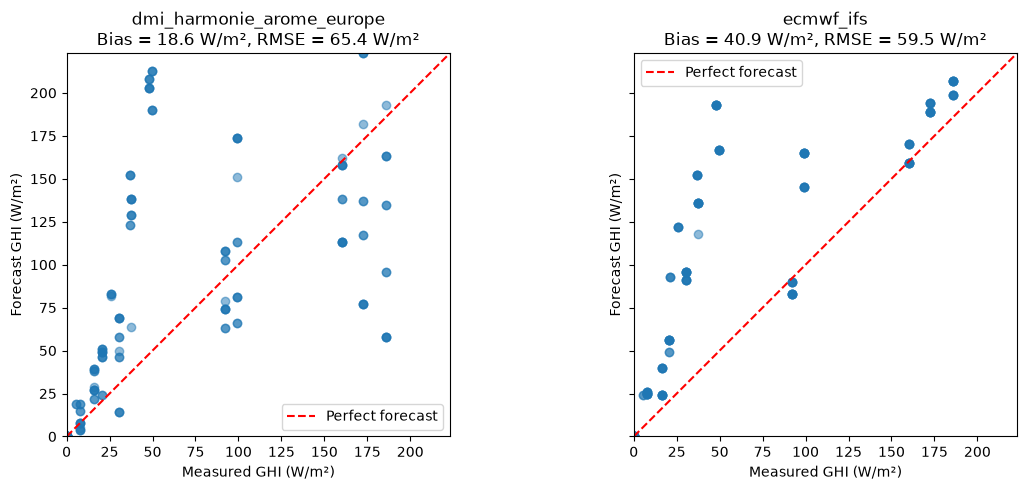

In [11]:
import math
import matplotlib.pyplot as plt

models = comparison["model"].unique()

ncols = 2
nrows = math.ceil(len(models) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(12, 5 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False,
)

axes = axes.flatten()

valid_comparison = comparison.dropna(
    subset=["ghi_measured", "ghi_forecast"]
)

axis_min = min(
    valid_comparison["ghi_measured"].min(),
    valid_comparison["ghi_forecast"].min(),
)
axis_max = max(
    valid_comparison["ghi_measured"].max(),
    valid_comparison["ghi_forecast"].max(),
)

for ax, model in zip(axes, models):
    model_data = valid_comparison.loc[
        valid_comparison["model"] == model
    ]

    error = model_data["ghi_forecast"] - model_data["ghi_measured"]
    bias = error.mean()
    rmse = (error.pow(2).mean()) ** 0.5

    ax.scatter(
        model_data["ghi_measured"],
        model_data["ghi_forecast"],
        alpha=0.5,
    )

    # Perfect forecast reference line
    ax.plot(
        [axis_min, axis_max],
        [axis_min, axis_max],
        color="red",
        linestyle="--",
        label="Perfect forecast",
    )

    ax.set_title(f"{model}\nBias = {bias:.1f} W/m², RMSE = {rmse:.1f} W/m²")
    ax.set_xlabel("Measured GHI (W/m²)")
    ax.set_ylabel("Forecast GHI (W/m²)")
    ax.legend()

    # Use the same scale on both axes to make the diagonal meaningful
    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.set_aspect("equal", adjustable="box")

# Hide any unused subplot panels
for ax in axes[len(models):]:
    ax.set_visible(False)

fig.tight_layout()
plt.show()